# UCU Data Mining and Wrangling - Group 2

## Jumia Nigeria seven-day analysis using genuine Daily Runs 1-7

**Project objective:** Analyse prices, ratings, reviews, discounts, brands and product visibility in the collected Jumia Nigeria sample.

**Categories:** Phones & Tablets, Computing and Electronics  
**Observation dates:** 13-19 October 2026 (`Africa/Nairobi`)  
**Scope:** 4,313 genuine observations from seven daily category-page collections. The results describe the collected sample, not the entire Jumia catalogue or Nigerian market.


## 1. Data source and database connection

The analysis uses `database/jumia_ng.sqlite` through a project-relative, read-only SQLite connection. This protects the verified database from accidental edits. The database keeps prices in Nigerian naira (NGN), so every price table and chart uses NGN even if a separate final CSV export is converted for presentation.

The analysis asks six questions:

1. What does the price distribution look like in each category?
2. Is there a relationship between price and rating, or between review count and rating?
3. How did product prices change across the full seven-day period?
4. What share of observations is discounted, and how did discounts change?
5. Which brands dominate each category?
6. Which products remained visible throughout all seven collection days, and how stable were their prices?


## 2. Setup

The next cells import the required libraries, define consistent chart settings and locate the repository without using a machine-specific absolute path.


In [16]:
from pathlib import Path
import platform
import sqlite3
from contextlib import closing

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

EXPECTED_CATEGORIES = {"Phones & Tablets", "Computing", "Electronics"}
CATEGORY_ORDER = ["Phones & Tablets", "Computing", "Electronics"]
CATEGORY_COLORS = {
    "Phones & Tablets": "#E07A5F",
    "Computing": "#3D5A80",
    "Electronics": "#2A9D8F",
}

def find_project_root() -> Path:
    for candidate in [Path.cwd(), Path.cwd().parent, Path.cwd().resolve()]:
        if (candidate / "database" / "jumia_ng.sqlite").exists():
            return candidate.resolve()
    raise FileNotFoundError("Run this notebook from the repository root or notebooks folder.")

def shorten(text, limit=46):
    text = str(text)
    return text if len(text) <= limit else text[: limit - 3] + "..."

def relationship_strength(value):
    magnitude = abs(float(value))
    if magnitude < 0.20:
        return "very weak"
    if magnitude < 0.40:
        return "weak"
    if magnitude < 0.60:
        return "moderate"
    if magnitude < 0.80:
        return "strong"
    return "very strong"


In [17]:
PROJECT_ROOT = find_project_root()
DATABASE_PATH = PROJECT_ROOT / "database" / "jumia_ng.sqlite"
database_uri = f"file:{DATABASE_PATH.as_posix()}?mode=ro"

with closing(sqlite3.connect(database_uri, uri=True)) as connection:
    database_counts = {
        table: connection.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
        for table in ("products", "categories", "product_categories", "observations")
    }
    database_integrity = connection.execute("PRAGMA integrity_check").fetchone()[0]
    foreign_key_violations = len(connection.execute("PRAGMA foreign_key_check").fetchall())
    database_duplicate_groups = connection.execute(
        '''
        SELECT COUNT(*) FROM (
            SELECT product_id, scrape_date, COUNT(*) AS records
            FROM observations
            GROUP BY product_id, scrape_date
            HAVING records > 1
        )
        '''
    ).fetchone()[0]
    database_date_counts = pd.read_sql_query(
        '''
        SELECT scrape_date, COUNT(*) AS observations
        FROM observations
        GROUP BY scrape_date
        ORDER BY scrape_date
        ''',
        connection,
    )
    df = pd.read_sql_query(
        '''
        SELECT
            p.source_product_id,
            p.product_name,
            p.brand,
            o.current_price,
            o.old_price,
            o.displayed_discount_percentage,
            o.calculated_discount_percentage,
            o.rating,
            o.review_count,
            (
                SELECT GROUP_CONCAT(c.category_name, ' | ')
                FROM product_categories AS pc
                JOIN categories AS c ON c.category_id = pc.category_id
                WHERE pc.product_id = p.product_id
            ) AS category,
            p.product_url,
            o.currency,
            p.source_site,
            o.scraped_at,
            o.scrape_date
        FROM observations AS o
        JOIN products AS p ON p.product_id = o.product_id
        ORDER BY o.scrape_date, o.scraped_at, p.source_product_id
        ''',
        connection,
    )

df["scrape_date"] = pd.to_datetime(df["scrape_date"])
available_dates = sorted(df["scrape_date"].unique())
date_labels = [pd.Timestamp(date).strftime("%Y-%m-%d") for date in available_dates]
run_label = f"{len(available_dates)} validated dates"

print("Project root located successfully; project-relative paths are in use.")
print(f"Read-only database: {DATABASE_PATH.relative_to(PROJECT_ROOT)}")
print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}; matplotlib: {matplotlib.__version__}; seaborn: {sns.__version__}")
print(f"Database counts: {database_counts}")
print(f"SQLite integrity: {database_integrity}; foreign-key violations: {foreign_key_violations}")
print(f"Observation dates loaded: {date_labels}")


Project root located successfully; project-relative paths are in use.
Read-only database: database\jumia_ng.sqlite
Python: 3.13.9
pandas: 2.3.3; matplotlib: 3.10.8; seaborn: 0.13.2
Database counts: {'products': 799, 'categories': 3, 'product_categories': 799, 'observations': 4313}
SQLite integrity: ok; foreign-key violations: 0
Observation dates loaded: ['2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17', '2026-10-18', '2026-10-19']


## 3. Seven-day dataset overview

**Question:** What data was collected across the seven days?

**Method:** Count observations, unique products, categories and dates. Product visibility is measured by the number of distinct collection dates on which each product was observed. Daily category totals are shown as collection coverage, not as Jumia's complete inventory.


In [18]:
category_date_counts = pd.crosstab(df["scrape_date"], df["category"]).reindex(columns=CATEGORY_ORDER)
days_per_product = df.groupby("source_product_id")["scrape_date"].nunique()

overview = pd.Series({
    "Total observations": len(df),
    "Unique products": df["source_product_id"].nunique(),
    "Categories": df["category"].nunique(),
    "Observation dates": df["scrape_date"].nunique(),
    "Products observed on all seven days": int((days_per_product == 7).sum()),
    "Products observed on only one day": int((days_per_product == 1).sum()),
    "Products observed on 2-6 days": int(days_per_product.between(2, 6).sum()),
})
display(overview.rename("count").to_frame())
display(database_date_counts)
display(category_date_counts)


,count
Total observations,4313
Unique products,799
Categories,3
Observation dates,7
Products observed on all seven days,469
Products observed on only one day,84
Products observed on 2-6 days,246


,scrape_date,observations
0,2026-10-13,639
1,2026-10-14,600
2,2026-10-15,639
3,2026-10-16,600
4,2026-10-17,635
5,2026-10-18,600
6,2026-10-19,600


category,Phones & Tablets,Computing,Electronics
scrape_date,,,
2026-10-13,239,200,200
2026-10-14,200,200,200
2026-10-15,239,200,200
2026-10-16,200,200,200
2026-10-17,238,198,199
2026-10-18,200,200,200
2026-10-19,200,200,200


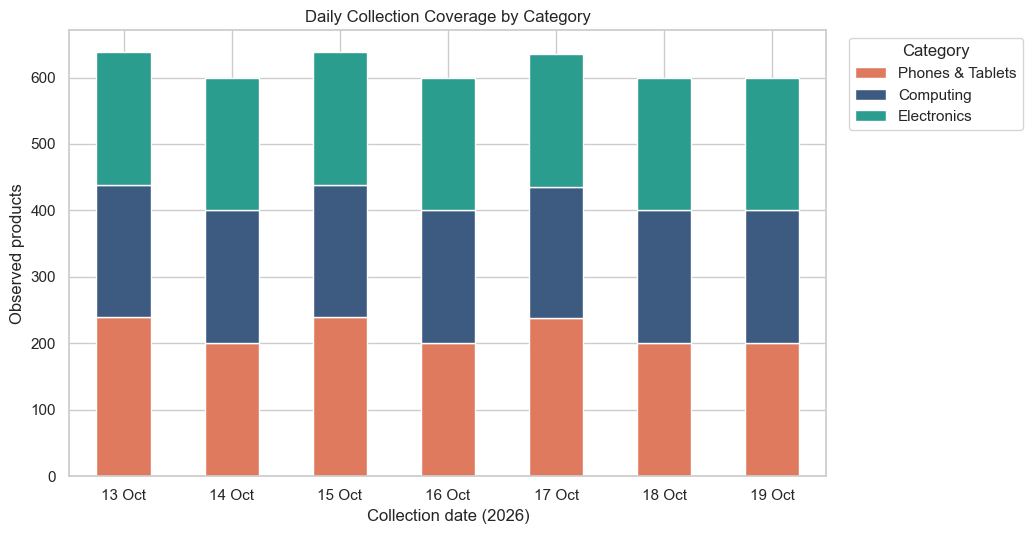

In [19]:
coverage_plot = category_date_counts.copy()
coverage_plot.index = coverage_plot.index.strftime("%d Oct")
axis = coverage_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10.5, 5.5),
    color=[CATEGORY_COLORS[column] for column in coverage_plot.columns],
)
axis.set_title("Daily Collection Coverage by Category")
axis.set_xlabel("Collection date (2026)")
axis.set_ylabel("Observed products")
axis.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


The collected sample contains 4,313 observations for 799 unique products across three categories and seven dates. Daily totals were 639, 600, 639, 600, 635, 600 and 600. Exactly 469 products were observed on all seven days, 84 appeared on only one day and 246 appeared on two to six days. Each date retains broad coverage of the three selected categories. Differences in daily counts describe the collected category pages and do not prove definite changes in Jumia's entire inventory.


## 4. Data-quality assessment

**Question:** Is the seven-day dataset complete and internally consistent enough for descriptive analysis?

**Method:** Report missing values without replacing them, check duplicate product/date rows, parse timestamps, test prices and ratings, and include SQLite integrity and foreign-key checks.


In [20]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
}).sort_values(["missing_count", "missing_percentage"], ascending=False)

parsed_timestamps = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)
nairobi_dates = parsed_timestamps.dt.tz_convert("Africa/Nairobi").dt.date
expected_dates = df["scrape_date"].dt.date

quality_checks = pd.Series({
    "Duplicate product/date rows": int(df.duplicated(["source_product_id", "scrape_date"]).sum()),
    "Duplicate product/timestamp rows": int(df.duplicated(["source_product_id", "scraped_at"]).sum()),
    "Missing or invalid timestamps": int(parsed_timestamps.isna().sum()),
    "Timestamp/date mismatches": int((nairobi_dates != expected_dates).sum()),
    "Non-positive current prices": int((df["current_price"] <= 0).sum()),
    "Negative old prices": int((df["old_price"] < 0).sum()),
    "Prices above NGN 1 billion": int(((df["current_price"] > 1_000_000_000) | (df["old_price"] > 1_000_000_000)).sum()),
    "Ratings outside 0-5": int(((df["rating"] < 0) | (df["rating"] > 5)).sum()),
    "Unexpected category values": int((~df["category"].isin(EXPECTED_CATEGORIES)).sum()),
    "Database duplicate product/date groups": int(database_duplicate_groups),
    "Database foreign-key violations": int(foreign_key_violations),
})

display(missing)
display(quality_checks.rename("count").to_frame())
print("SQLite integrity status:", database_integrity)
print("Category set matches expectation:", set(df["category"].unique()) == EXPECTED_CATEGORIES)


,missing_count,missing_percentage
old_price,199,4.61
displayed_discount_percentage,199,4.61
calculated_discount_percentage,199,4.61
rating,25,0.58
review_count,25,0.58
source_product_id,0,0.00
product_name,0,0.00
brand,0,0.00
current_price,0,0.00
category,0,0.00


,count
Duplicate product/date rows,0
Duplicate product/timestamp rows,0
Missing or invalid timestamps,0
Timestamp/date mismatches,0
Non-positive current prices,0
Negative old prices,0
Prices above NGN 1 billion,0
Ratings outside 0-5,0
Unexpected category values,0
Database duplicate product/date groups,0


SQLite integrity status: ok
Category set matches expectation: True


The database passes its integrity check and has no foreign-key violations or duplicate product/date groups. All timestamps parse correctly and match their Nairobi collection dates. Current prices are positive, available old prices are non-negative, and all available ratings fall between 0 and 5.

Missing values remain genuine missing values: 199 observations have no old price or discount evidence, while 25 have no rating or review count. They are not replaced with zero because zero would claim that Jumia displayed information that was absent.


## 5. Price distribution and outliers

**Question:** What does the price distribution look like in each category?

**Method:** Calculate count, mean, median, minimum, maximum, quartiles and IQR by category. An outlier is below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`. Outliers are identified but not removed. Logarithmic price axes make the strongly right-skewed distributions readable.


In [21]:
price_summary = df.groupby("category")["current_price"].agg(
    count="count",
    mean="mean",
    median="median",
    minimum="min",
    maximum="max",
    q1=lambda values: values.quantile(0.25),
    q3=lambda values: values.quantile(0.75),
)
price_summary["iqr"] = price_summary["q3"] - price_summary["q1"]
price_summary["lower_boundary"] = price_summary["q1"] - 1.5 * price_summary["iqr"]
price_summary["upper_boundary"] = price_summary["q3"] + 1.5 * price_summary["iqr"]

outlier_counts = {}
for category, row in price_summary.iterrows():
    prices = df.loc[df["category"] == category, "current_price"]
    outlier_counts[category] = int(
        ((prices < row["lower_boundary"]) | (prices > row["upper_boundary"])).sum()
    )
price_summary["outliers"] = pd.Series(outlier_counts)
display(price_summary.round(2))


,count,mean,median,minimum,maximum,q1,q3,iqr,lower_boundary,upper_boundary,outliers
category,,,,,,,,,,,
Computing,1398,"50,448.97","6,451.00",907.00,"2,066,198.00","3,300.00","13,900.00","10,600.00","-12,600.00","29,800.00",153
Electronics,1399,"68,892.17","21,619.00",804.00,"799,889.00","6,000.00","72,000.00","66,000.00","-93,000.00","171,000.00",157
Phones & Tablets,1516,"31,285.62","9,900.00","1,567.00","314,517.00","6,211.00","20,842.00","14,631.00","-15,735.50","42,788.50",201


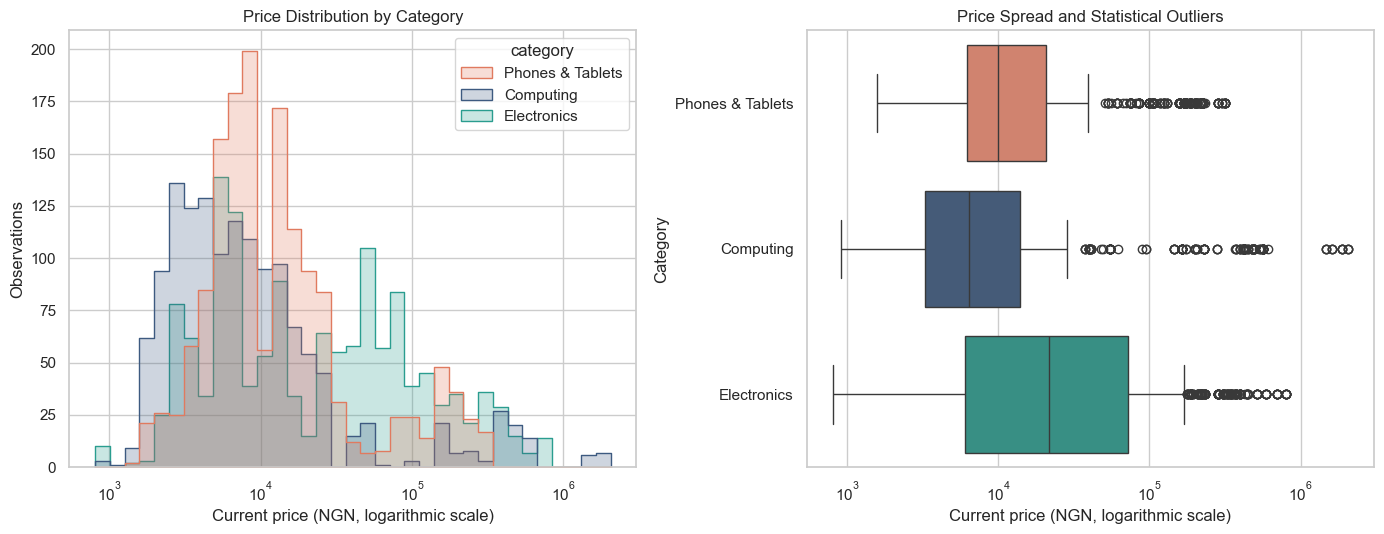

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.histplot(
    data=df,
    x="current_price",
    hue="category",
    hue_order=CATEGORY_ORDER,
    palette=CATEGORY_COLORS,
    bins=35,
    element="step",
    common_norm=False,
    log_scale=(True, False),
    ax=axes[0],
)
axes[0].set_title("Price Distribution by Category")
axes[0].set_xlabel("Current price (NGN, logarithmic scale)")
axes[0].set_ylabel("Observations")

sns.boxplot(
    data=df,
    x="current_price",
    y="category",
    order=CATEGORY_ORDER,
    hue="category",
    palette=CATEGORY_COLORS,
    legend=False,
    ax=axes[1],
)
axes[1].set_xscale("log")
axes[1].set_title("Price Spread and Statistical Outliers")
axes[1].set_xlabel("Current price (NGN, logarithmic scale)")
axes[1].set_ylabel("Category")
plt.tight_layout()
plt.show()


The collected sample suggests strongly right-skewed prices in every category. Electronics has the highest typical price, with a median of NGN 21,619. Computing has the greatest overall spread and the highest observed price, NGN 2,066,198, even though its median is only NGN 6,451. Phones & Tablets has a median of NGN 9,900. The IQR rule identifies 153 Computing, 157 Electronics and 201 Phones & Tablets observations as outliers. These observations are not deleted because genuine expensive laptops, televisions and phones can be statistically unusual without being data errors.


## 6. Price, rating and review relationships

**Question:** Is there a relationship between price and rating, or between review count and rating?

**Method:** Use each product's latest complete observation so products seen repeatedly are not over-weighted. Spearman correlation is used because prices and review counts are skewed. Review count is used only as a limited popularity proxy. Correlation describes association and does not prove causation.


,Spearman correlation
Complete latest products,794.00
Price versus rating,0.11
Review count versus rating,-0.21
Price versus review count,-0.12


,complete_products,price_vs_rating,review_count_vs_rating,price_vs_review_count
category,,,,
Computing,251,-0.05,-0.03,-0.19
Electronics,260,0.16,0.06,0.02
Phones & Tablets,283,0.43,-0.17,-0.16


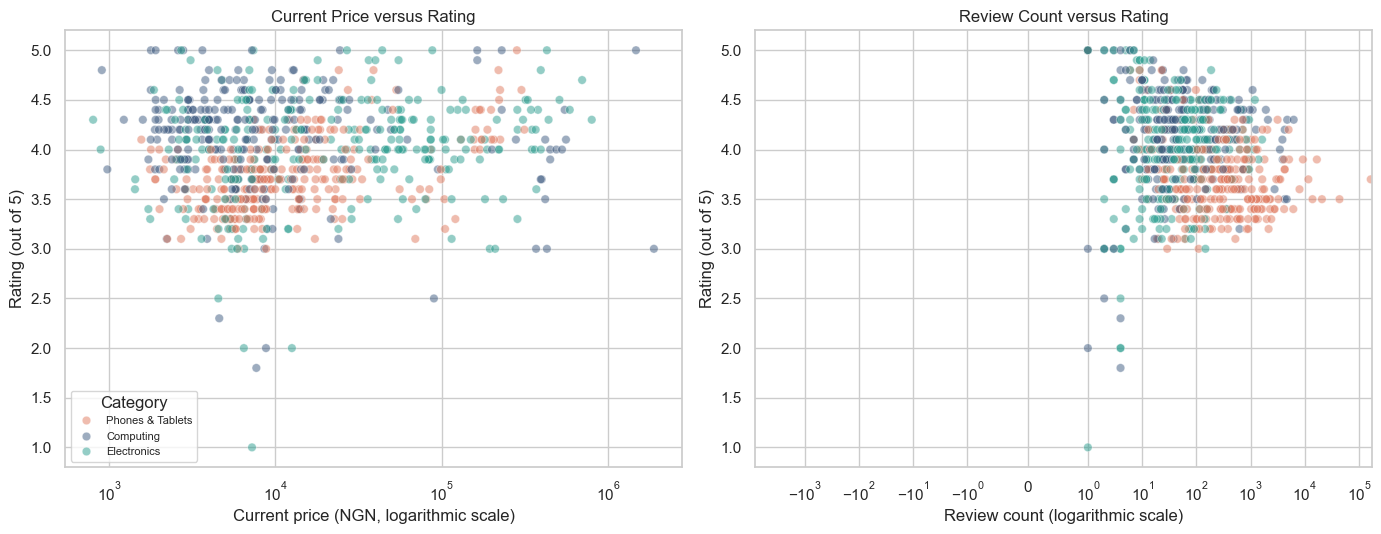

In [23]:
latest_products = (
    df.sort_values(["scrape_date", "scraped_at"])
      .drop_duplicates("source_product_id", keep="last")
)
relationship_data = latest_products.dropna(
    subset=["current_price", "rating", "review_count"]
).copy()
relationship_columns = ["current_price", "rating", "review_count"]
overall_correlations = relationship_data[relationship_columns].corr(method="spearman")

category_correlations = []
for category, subset in relationship_data.groupby("category"):
    correlations = subset[relationship_columns].corr(method="spearman")
    category_correlations.append({
        "category": category,
        "complete_products": len(subset),
        "price_vs_rating": correlations.loc["current_price", "rating"],
        "review_count_vs_rating": correlations.loc["review_count", "rating"],
        "price_vs_review_count": correlations.loc["current_price", "review_count"],
    })
category_correlations = pd.DataFrame(category_correlations).set_index("category")

relationship_summary = pd.Series({
    "Complete latest products": len(relationship_data),
    "Price versus rating": overall_correlations.loc["current_price", "rating"],
    "Review count versus rating": overall_correlations.loc["review_count", "rating"],
    "Price versus review count": overall_correlations.loc["current_price", "review_count"],
})
display(relationship_summary.rename("Spearman correlation").to_frame().round(3))
display(category_correlations.round(3))

figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(
    data=relationship_data,
    x="current_price",
    y="rating",
    hue="category",
    hue_order=CATEGORY_ORDER,
    palette=CATEGORY_COLORS,
    alpha=0.50,
    s=38,
    ax=axes[0],
)
axes[0].set_xscale("log")
axes[0].set_title("Current Price versus Rating")
axes[0].set_xlabel("Current price (NGN, logarithmic scale)")
axes[0].set_ylabel("Rating (out of 5)")
axes[0].legend(title="Category", fontsize=8)

sns.scatterplot(
    data=relationship_data,
    x="review_count",
    y="rating",
    hue="category",
    hue_order=CATEGORY_ORDER,
    palette=CATEGORY_COLORS,
    alpha=0.50,
    s=38,
    legend=False,
    ax=axes[1],
)
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set_title("Review Count versus Rating")
axes[1].set_xlabel("Review count (logarithmic scale)")
axes[1].set_ylabel("Rating (out of 5)")
plt.tight_layout()
plt.show()


Overall price versus rating is **very weak and positive** (`ρ = 0.110`). Review count versus rating is **weak and negative** (`ρ = -0.215`), while price versus review count is **very weak and negative** (`ρ = -0.118`). The category results differ: Phones & Tablets shows a moderate positive price-rating relationship (`ρ = 0.435`), while the other categories remain very weak. These associations do not show that price or popularity caused a rating.


## 7. Seven-day price changes

**Question:** How did product prices change across the full seven-day period?

**Method:** For every product with at least two valid prices, compare its first and last observations, retain its minimum and maximum prices, and count changes between consecutive observed dates. Percentage change is calculated only when the first price is greater than zero.


In [24]:
movement_rows = []
for product_id, product_rows in df.groupby("source_product_id", sort=False):
    valid = product_rows.dropna(subset=["current_price"]).sort_values(
        ["scrape_date", "scraped_at"]
    )
    if len(valid) < 2:
        continue
    first = valid.iloc[0]
    last = valid.iloc[-1]
    first_price = float(first["current_price"])
    last_price = float(last["current_price"])
    price_change = last_price - first_price
    movement_rows.append({
        "source_product_id": product_id,
        "product_name": last["product_name"],
        "category": last["category"],
        "first_observed_date": first["scrape_date"],
        "last_observed_date": last["scrape_date"],
        "first_valid_price": first_price,
        "last_valid_price": last_price,
        "minimum_observed_price": float(valid["current_price"].min()),
        "maximum_observed_price": float(valid["current_price"].max()),
        "first_to_last_change": price_change,
        "percentage_change": price_change / first_price * 100 if first_price > 0 else np.nan,
        "dates_observed": int(valid["scrape_date"].nunique()),
        "recorded_price_changes": int(valid["current_price"].ne(valid["current_price"].shift()).iloc[1:].sum()),
    })
movement = pd.DataFrame(movement_rows)

movement_summary = pd.Series({
    "Products with at least two valid prices": len(movement),
    "First-to-last increases": int((movement["first_to_last_change"] > 0).sum()),
    "First-to-last decreases": int((movement["first_to_last_change"] < 0).sum()),
    "First-to-last unchanged": int((movement["first_to_last_change"] == 0).sum()),
    "Products with any recorded price change": int((movement["recorded_price_changes"] > 0).sum()),
    "Total genuine recorded price changes": int(movement["recorded_price_changes"].sum()),
})
top_absolute_increases = movement[movement["first_to_last_change"] > 0].nlargest(5, "first_to_last_change")
top_absolute_decreases = movement[movement["first_to_last_change"] < 0].nsmallest(5, "first_to_last_change")
top_percentage_increases = movement[movement["percentage_change"] > 0].nlargest(5, "percentage_change")
top_percentage_decreases = movement[movement["percentage_change"] < 0].nsmallest(5, "percentage_change")

display(movement_summary.rename("count").to_frame())
print("Top five absolute increases")
display(top_absolute_increases[["product_name", "category", "first_valid_price", "last_valid_price", "first_to_last_change", "percentage_change"]].round(2))
print("Top five absolute decreases")
display(top_absolute_decreases[["product_name", "category", "first_valid_price", "last_valid_price", "first_to_last_change", "percentage_change"]].round(2))
print("Largest valid percentage increases")
display(top_percentage_increases[["product_name", "category", "percentage_change"]].round(2))
print("Largest valid percentage decreases")
display(top_percentage_decreases[["product_name", "category", "percentage_change"]].round(2))


,count
Products with at least two valid prices,715
First-to-last increases,48
First-to-last decreases,252
First-to-last unchanged,415
Products with any recorded price change,314
Total genuine recorded price changes,378


Top five absolute increases


,product_name,category,first_valid_price,last_valid_price,first_to_last_change,percentage_change
388,Asus Vivobook Go 14-Intel N150-8GB Ram-256GB SSD-14 inches-FHD (19...,Computing,"437,900.00","477,381.00","39,481.00",9.02
42,DELL Latitude 7490 Intel Core I5- 16GB RAM/256GB SSD /BACKLIGHT KE...,Computing,"416,860.00","430,000.00","13,140.00",3.15
598,Oraimo BoomPop Pro Wireless Headphones Over-Ear Hybrid Noise Cance...,Phones & Tablets,"38,313.00","50,899.00","12,586.00",32.85
97,Hikers 43'' Inches Smart Frameless A+ Panel FHD Smart LED TV-Black...,Electronics,"169,999.00","181,666.00","11,667.00",6.86
20,Oraimo Traveler 15 Power Bank 20000mAh 15W Type-C Fast Charging wi...,Phones & Tablets,"13,500.00","19,500.00","6,000.00",44.44


Top five absolute decreases


,product_name,category,first_valid_price,last_valid_price,first_to_last_change,percentage_change
38,Asus TUF Gaming Laptop A16-AMD Ryzen 7 260-16GB Ram-512GB SSD-NV G...,Computing,"2,066,198.00","1,891,600.00","-174,598.00",-8.45
23,"OUKITEL C66 Smartphone,16GB(4+12)RAM+128GB ROM,6.73""HD,64MP AI pho...",Phones & Tablets,"187,000.00","156,600.00","-30,400.00",-16.26
525,Hp Stream 11 PRO Intel Celeron 4GB RAM- 64GB SSD WIN 10+ USB LIGHT...,Computing,"174,000.00","145,000.00","-29,000.00",-16.67
403,USB - interface Headset with Microphone Noise - canceling for Comp...,Computing,"40,320.00","14,900.00","-25,420.00",-63.05
109,Royal 50″ Inch QLED GOOGLE TV + FREE WALL BRACKET - 12 Months Warr...,Electronics,"339,499.00","319,999.00","-19,500.00",-5.74


Largest valid percentage increases


,product_name,category,percentage_change
2,Kingnote 2.09''inch T900U Smartwatch Native Storm Waterproof Black,Phones & Tablets,72.31
216,"Portable Wireless Bluetooth 5.2 Stereo Speaker, 1200mAh Rechargeab...",Electronics,48.15
469,Kingnote 2.09''inch T900U Smart Watch Dual Band 2-in-1 With Blueto...,Phones & Tablets,44.49
20,Oraimo Traveler 15 Power Bank 20000mAh 15W Type-C Fast Charging wi...,Phones & Tablets,44.44
156,Kingnote 2.4G Rechargeable Wireless Mouse Bluetooth 2 Modes,Computing,33.33


Largest valid percentage decreases


,product_name,category,percentage_change
46,Metal Foldable Adjustable Stand Holder For Laptop,Computing,-63.59
403,USB - interface Headset with Microphone Noise - canceling for Comp...,Computing,-63.05
393,5 in 1 Multifunction USB 2.0 Type C USB Micro USB SD TF Memory Car...,Computing,-62.49
165,7 Inch Wireless Bluetooth Keyboard For Phone And Tablet-VSC,Computing,-50.00
292,"Portable Voice Changer and Mini Live Sound Card for Phone, PC and ...",Computing,-50.00


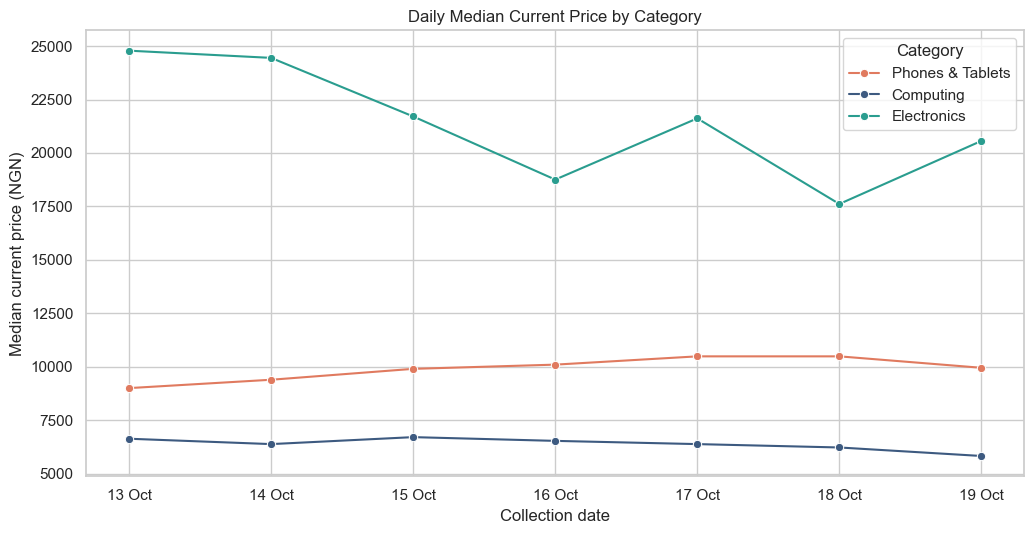

In [25]:
daily_median_prices = (
    df.groupby(["scrape_date", "category"], as_index=False)["current_price"].median()
)
plt.figure(figsize=(10.5, 5.5))
sns.lineplot(
    data=daily_median_prices,
    x="scrape_date",
    y="current_price",
    hue="category",
    hue_order=CATEGORY_ORDER,
    palette=CATEGORY_COLORS,
    marker="o",
)
plt.title("Daily Median Current Price by Category")
plt.xlabel("Collection date")
plt.ylabel("Median current price (NGN)")
plt.xticks(available_dates, [pd.Timestamp(date).strftime("%d Oct") for date in available_dates], rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()


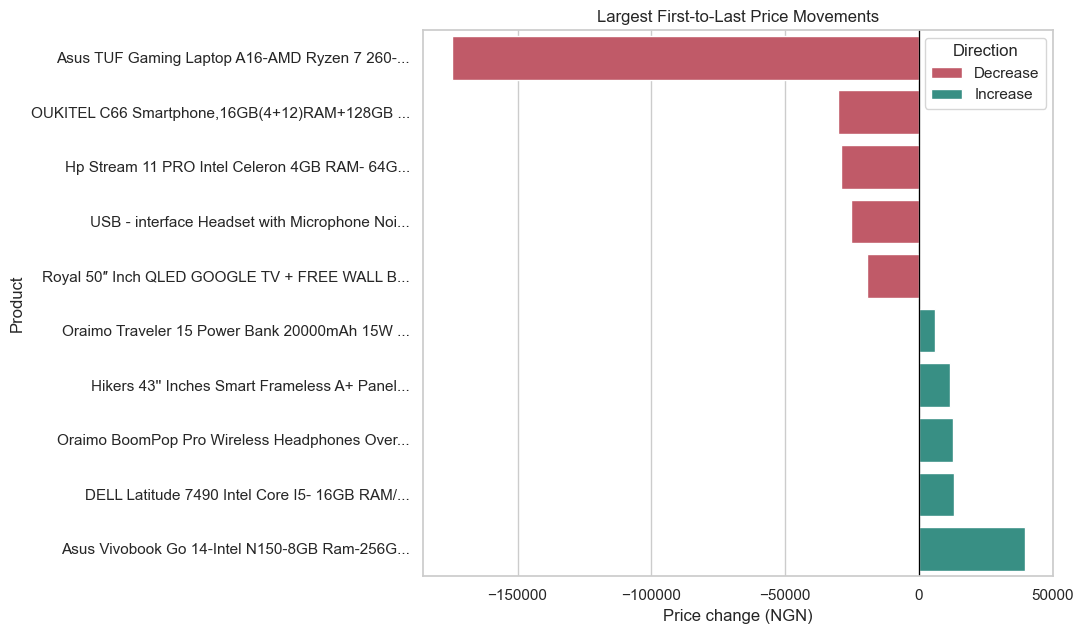

In [26]:
movement_chart = pd.concat([top_absolute_increases, top_absolute_decreases], ignore_index=True).copy()
movement_chart["short_name"] = movement_chart["product_name"].map(shorten)
movement_chart = movement_chart.sort_values("first_to_last_change")
movement_chart["direction"] = np.where(
    movement_chart["first_to_last_change"] >= 0,
    "Increase",
    "Decrease",
)

plt.figure(figsize=(11, 6.5))
axis = sns.barplot(
    data=movement_chart,
    x="first_to_last_change",
    y="short_name",
    hue="direction",
    palette={"Increase": "#2A9D8F", "Decrease": "#D1495B"},
    dodge=False,
)
axis.axvline(0, color="black", linewidth=0.9)
axis.set_title("Largest First-to-Last Price Movements")
axis.set_xlabel("Price change (NGN)")
axis.set_ylabel("Product")
axis.legend(title="Direction")
plt.tight_layout()
plt.show()


Among 715 products with at least two valid prices, 48 increased, 252 decreased and 415 ended unchanged between their first and last observations. However, 314 products changed at least once during the period, producing 378 genuine consecutive-observation changes. The largest absolute increase was NGN 39,481 for an Asus Vivobook, while the largest absolute decrease was NGN 174,598 for an Asus TUF gaming laptop. The largest percentage increase was 72.31%, and the largest percentage decrease was 63.59%.

Daily category medians are descriptive. A change can reflect an actual product-price change, a different mixture of products appearing in the daily sample, or both.


## 8. Discount analysis

**Question:** What share of observations is discounted, and how did discounts change during the seven days?

**Method:** Preserve missing discounts, calculate actual discount only where both prices exist and old price is greater than zero, compare displayed and calculated discounts, and compare the first and last available discount evidence for each product with at least two valid discount observations.

`Actual discount = ((old price - current price) / old price) × 100`


Observations with an old price: 4,114
Observations with a displayed discount: 4,114
Discounted share overall: 95.39%


,observations,observations_with_old_price,observations_with_displayed_discount,median_displayed_discount,median_actual_discount,discounted_share
category,,,,,,
Computing,1398,1267,1267,50.00,50.00,90.63
Electronics,1399,1343,1343,42.00,41.85,96.00
Phones & Tablets,1516,1504,1504,50.00,50.00,99.21


,displayed_discount,calculated_discount
comparable_products,682,682
increased,227,243
decreased,44,45
unchanged,411,394


,product_name,category,first_discount,last_discount,discount_change
98,EAGEAT 900*400mm Oversized Mouse Pad Mat,Computing,18.00,59.00,41.00
187,7 Inch Wireless Bluetooth Keyboard For Phone And Tablet-VSC,Computing,44.00,72.00,28.00
274,"Portable Voice Changer and Mini Live Sound Card for Phone, PC and ...",Computing,46.00,73.00,27.00
534,Oraimo Traveler 15 Power Bank 20000mAh 15W Type-C Fast Charging wi...,Phones & Tablets,51.00,29.00,-22.00
161,TWO (2) NON RECHARGEABLE USB LED BULBS Lights / LIGHT FOR COMPUTER...,Computing,40.00,19.00,-21.00
652,Yaticrab 4G LTE USB Modem WiFi | 150Mbps Speed | Driver - Free | M...,Computing,30.00,51.00,21.00
545,Oraimo PowerNova Q21 Power Bank 20000mAh 22.5W Fast Charging Smart...,Phones & Tablets,31.00,10.00,-21.00
206,"Smart Watch Bands 2.09""IPS Touch Screen Heart Rate Monitor Waterpr...",Phones & Tablets,33.00,53.00,20.00
142,900*400mm Oversized Mouse Pad World Map Non-slip Keyboard Pad Desk...,Computing,36.00,55.00,19.00
178,2.4GHz Mechanical Keyboard Wireless Slim Keyboard Mouse Kit - White,Computing,25.00,44.00,19.00


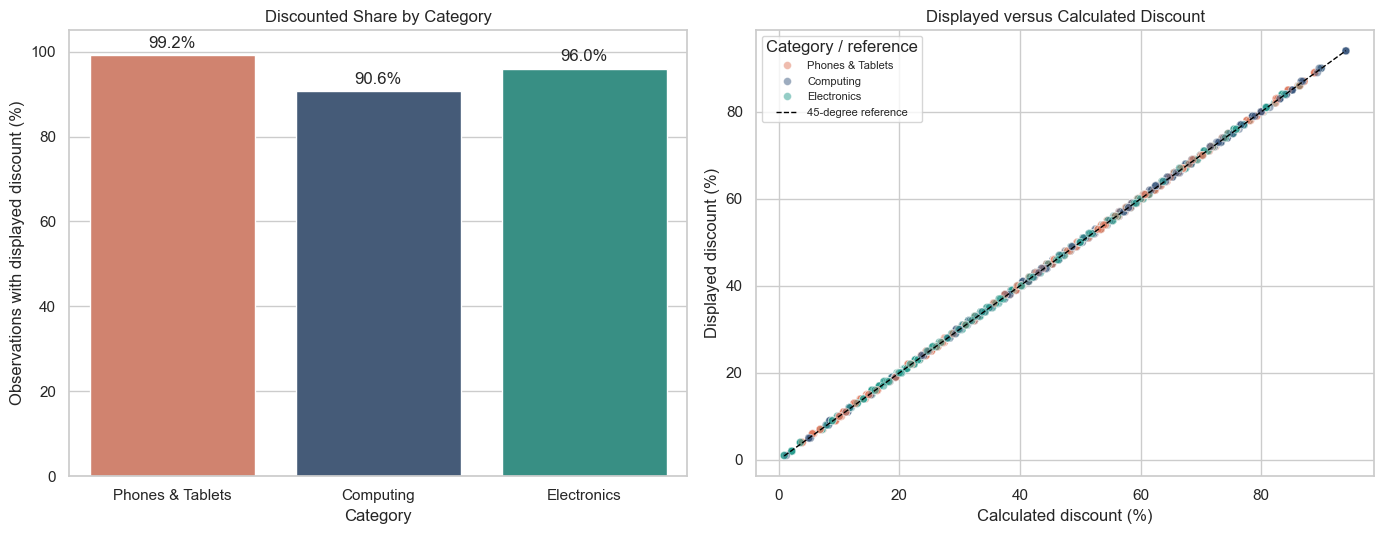

In [27]:
valid_actual_discount = (
    df["old_price"].notna()
    & df["current_price"].notna()
    & (df["old_price"] > 0)
)
df["actual_discount"] = np.where(
    valid_actual_discount,
    (df["old_price"] - df["current_price"]) / df["old_price"] * 100,
    np.nan,
)

discount_summary = df.groupby("category").agg(
    observations=("source_product_id", "size"),
    observations_with_old_price=("old_price", "count"),
    observations_with_displayed_discount=("displayed_discount_percentage", "count"),
    median_displayed_discount=("displayed_discount_percentage", "median"),
    median_actual_discount=("actual_discount", "median"),
)
discount_summary["discounted_share"] = (
    discount_summary["observations_with_displayed_discount"]
    / discount_summary["observations"]
    * 100
)

def build_discount_movement(column):
    rows = []
    for product_id, product_rows in df.dropna(subset=[column]).groupby("source_product_id"):
        product_rows = product_rows.sort_values(["scrape_date", "scraped_at"])
        if len(product_rows) < 2:
            continue
        first = product_rows.iloc[0]
        last = product_rows.iloc[-1]
        rows.append({
            "source_product_id": product_id,
            "product_name": last["product_name"],
            "category": last["category"],
            "first_discount": float(first[column]),
            "last_discount": float(last[column]),
            "discount_change": float(last[column] - first[column]),
            "dates_with_evidence": int(product_rows["scrape_date"].nunique()),
        })
    return pd.DataFrame(rows)

displayed_discount_movement = build_discount_movement("displayed_discount_percentage")
calculated_discount_movement = build_discount_movement("actual_discount")

discount_movement_summary = pd.DataFrame({
    "displayed_discount": {
        "comparable_products": len(displayed_discount_movement),
        "increased": int((displayed_discount_movement["discount_change"] > 0).sum()),
        "decreased": int((displayed_discount_movement["discount_change"] < 0).sum()),
        "unchanged": int((displayed_discount_movement["discount_change"] == 0).sum()),
    },
    "calculated_discount": {
        "comparable_products": len(calculated_discount_movement),
        "increased": int((calculated_discount_movement["discount_change"] > 0).sum()),
        "decreased": int((calculated_discount_movement["discount_change"] < 0).sum()),
        "unchanged": int((calculated_discount_movement["discount_change"] == 0).sum()),
    },
})
largest_discount_changes = displayed_discount_movement.reindex(
    displayed_discount_movement["discount_change"].abs().sort_values(ascending=False).index
).head(10)

print(f"Observations with an old price: {df['old_price'].notna().sum():,}")
print(f"Observations with a displayed discount: {df['displayed_discount_percentage'].notna().sum():,}")
print(f"Discounted share overall: {df['displayed_discount_percentage'].notna().mean() * 100:.2f}%")
display(discount_summary.round(2))
display(discount_movement_summary)
display(largest_discount_changes[["product_name", "category", "first_discount", "last_discount", "discount_change"]].round(2))

discount_pairs = df.dropna(subset=["displayed_discount_percentage", "actual_discount"]).copy()
figure, axes = plt.subplots(1, 2, figsize=(14, 5.5))
share_frame = discount_summary.reset_index()
share_axis = sns.barplot(
    data=share_frame,
    x="category",
    y="discounted_share",
    order=CATEGORY_ORDER,
    hue="category",
    palette=CATEGORY_COLORS,
    legend=False,
    ax=axes[0],
)
for container in share_axis.containers:
    share_axis.bar_label(container, fmt="%.1f%%", padding=3)
axes[0].set_title("Discounted Share by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Observations with displayed discount (%)")
axes[0].set_ylim(0, 105)

sns.scatterplot(
    data=discount_pairs,
    x="actual_discount",
    y="displayed_discount_percentage",
    hue="category",
    hue_order=CATEGORY_ORDER,
    palette=CATEGORY_COLORS,
    alpha=0.50,
    s=32,
    ax=axes[1],
)
lower = min(discount_pairs["actual_discount"].min(), discount_pairs["displayed_discount_percentage"].min())
upper = max(discount_pairs["actual_discount"].max(), discount_pairs["displayed_discount_percentage"].max())
axes[1].plot([lower, upper], [lower, upper], "--", color="black", linewidth=1, label="45-degree reference")
axes[1].set_title("Displayed versus Calculated Discount")
axes[1].set_xlabel("Calculated discount (%)")
axes[1].set_ylabel("Displayed discount (%)")
axes[1].legend(title="Category / reference", fontsize=8)
plt.tight_layout()
plt.show()


Old-price and displayed-discount evidence exists for 4,114 of 4,313 observations, giving an overall discounted share of 95.39%. Shares are 90.63% in Computing, 96.00% in Electronics and 99.21% in Phones & Tablets. Median displayed discounts are 50%, 42% and 50% respectively.

Among 682 products with comparable displayed-discount evidence, 227 discounts increased, 44 decreased and 411 were unchanged from first to last evidence. Calculated discounts increased for 243 products, decreased for 45 and remained unchanged for 394. The largest displayed change was a 41-percentage-point increase. Small differences between displayed and calculated discounts may result from rounding, changing reference prices or display inconsistencies; missing evidence is never treated as zero.


## 9. Brand dominance

**Question:** Which brands dominate each category?

**Method:** Count unique products for each brand-category pair and divide by all unique products in that category. Repeated daily observations are not counted as extra products. Missing or blank brands are labelled `Unknown` for the check.


Unique products with missing/unknown brand: 0


,category,brand_clean,unique_products,brand_share
10,Computing,Generic,127,50.00
5,Computing,EAGEAT,9,3.54
9,Computing,GUEETON,9,3.54
13,Computing,Hp,9,3.54
21,Computing,Logitech,8,3.15
65,Electronics,Generic,103,39.31
80,Electronics,Mi+,28,10.69
106,Electronics,Zealot,18,6.87
71,Electronics,Hisense,9,3.44
108,Electronics,itel,7,2.67


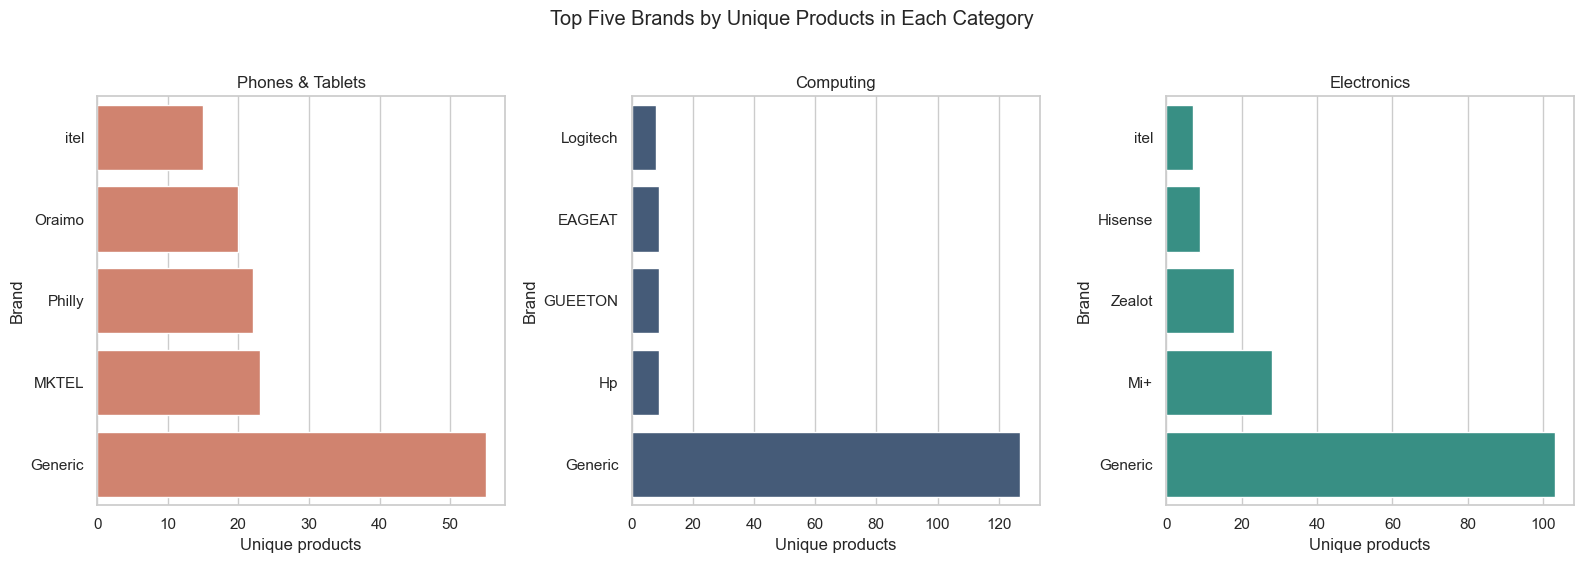

In [28]:
unique_brand_products = df.drop_duplicates(["category", "source_product_id"]).copy()
unique_brand_products["brand_clean"] = (
    unique_brand_products["brand"].fillna("Unknown").replace("", "Unknown")
)
brand_summary = (
    unique_brand_products.groupby(["category", "brand_clean"])
    .size()
    .rename("unique_products")
    .reset_index()
)
brand_summary["brand_share"] = (
    brand_summary["unique_products"]
    / brand_summary.groupby("category")["unique_products"].transform("sum")
    * 100
)
top_brands = (
    brand_summary.sort_values(["category", "unique_products"], ascending=[True, False])
    .groupby("category", group_keys=False)
    .head(5)
)
print("Unique products with missing/unknown brand:", int((unique_brand_products["brand_clean"] == "Unknown").sum()))
display(top_brands.round(2))

figure, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for axis, category in zip(axes, CATEGORY_ORDER):
    subset = top_brands[top_brands["category"] == category].sort_values("unique_products")
    sns.barplot(
        data=subset,
        x="unique_products",
        y="brand_clean",
        color=CATEGORY_COLORS[category],
        ax=axis,
    )
    axis.set_title(category)
    axis.set_xlabel("Unique products")
    axis.set_ylabel("Brand")
figure.suptitle("Top Five Brands by Unique Products in Each Category", y=1.02)
plt.tight_layout()
plt.show()


`Generic` dominates the observed unique-product counts in every category: 127 Computing products (50.00%), 103 Electronics products (39.31%) and 55 Phones & Tablets products (19.43%). Other visible leaders include EAGEAT, GUEETON and Hp in Computing; Mi+, Zealot and Hisense in Electronics; and MKTEL, Philly and Oraimo in Phones & Tablets. No unique product has a missing brand. These shares describe listing presence in the collected sample, not sales or market share.


## 10. Product visibility and price stability

**Original group question:** Which products remained visible throughout all seven collection days, and how stable were their prices?

**Method:** Count the distinct days each product was observed. For products observed at least twice, calculate price range and percentage price range. Percentage range is calculated only when minimum price is greater than zero.

`Percentage price range = ((maximum price - minimum price) / minimum price) × 100`

“Not observed” means not visible on the collected category pages for that daily sample; it does not mean the product was definitely out of stock.


,days_observed,products
0,1,84
1,2,56
2,3,59
3,4,47
4,5,35
5,6,49
6,7,469


Repeatedly observed products: 715
Repeated products with zero price range: 401
Most stable products with a non-zero movement


,product_name,category,dates_observed,price_range,percentage_price_range
560,"Hisense 65"" UHD 4K SMART TV, 3 HDMI, 2 USB, 1 AV, Free Wall Bracke...",Electronics,7,9.00,0.00
464,Zealot 250W Super Bass Bluetooth Speaker With 48000mAh Battery S89,Electronics,7,500.00,0.21
339,"Hisense 55"" Inches UHD 4K SMART TV (55A6N /55A6Q) - Black + 1 Year...",Electronics,7,"2,274.00",0.44
265,"redbeat D5 Android 14 Smartphones 4+64GB ROM, 6.52 inch, 5000mAh/D...",Phones & Tablets,7,405.00,0.48
701,Mini Wireless WIFI Hidden Camera Suitable For Safety - Black,Electronics,3,28.00,0.51


Least price-stable products


,product_name,category,dates_observed,price_range,percentage_price_range
46,Metal Foldable Adjustable Stand Holder For Laptop,Computing,7,"2,148.00",174.63
403,USB - interface Headset with Microphone Noise - canceling for Comp...,Computing,6,"25,420.00",170.60
393,5 in 1 Multifunction USB 2.0 Type C USB Micro USB SD TF Memory Car...,Computing,7,"3,715.00",166.59
121,4 pcs Carbon Fingers Sleeve Anti Sweat Gamer Finger Covers for All...,Phones & Tablets,7,"2,451.00",138.63
165,7 Inch Wireless Bluetooth Keyboard For Phone And Tablet-VSC,Computing,7,"3,996.00",100.00


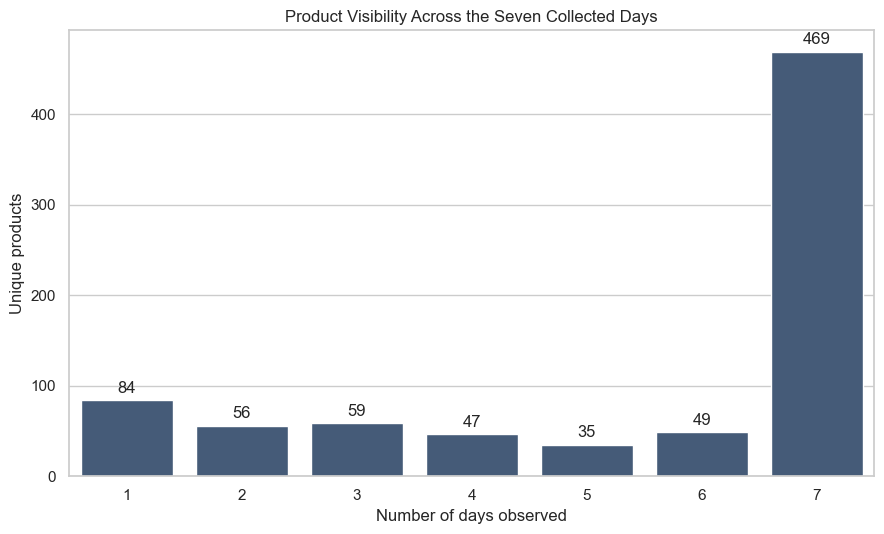

In [29]:
visibility_distribution = (
    days_per_product.value_counts()
    .reindex(range(1, 8), fill_value=0)
    .rename_axis("days_observed")
    .rename("products")
    .reset_index()
)
stability = movement.copy()
stability["price_range"] = (
    stability["maximum_observed_price"] - stability["minimum_observed_price"]
)
stability["percentage_price_range"] = np.where(
    stability["minimum_observed_price"] > 0,
    stability["price_range"] / stability["minimum_observed_price"] * 100,
    np.nan,
)
most_stable_nonzero = stability[stability["percentage_price_range"] > 0].nsmallest(
    5, "percentage_price_range"
)
least_stable = stability.nlargest(5, "percentage_price_range")

display(visibility_distribution)
print(f"Repeatedly observed products: {len(stability):,}")
print(f"Repeated products with zero price range: {(stability['price_range'] == 0).sum():,}")
print("Most stable products with a non-zero movement")
display(most_stable_nonzero[["product_name", "category", "dates_observed", "price_range", "percentage_price_range"]].round(2))
print("Least price-stable products")
display(least_stable[["product_name", "category", "dates_observed", "price_range", "percentage_price_range"]].round(2))

plt.figure(figsize=(9, 5.5))
axis = sns.barplot(
    data=visibility_distribution,
    x="days_observed",
    y="products",
    color="#3D5A80",
)
axis.bar_label(axis.containers[0], padding=3)
axis.set_title("Product Visibility Across the Seven Collected Days")
axis.set_xlabel("Number of days observed")
axis.set_ylabel("Unique products")
plt.tight_layout()
plt.show()


Exactly 469 products remained visible in the collected sample on all seven days. Another 84 appeared on only one day, while 246 appeared on two to six days. Among 715 products observed at least twice, 401 had a zero price range. The least stable product had a 174.63% price range relative to its minimum observed price. These findings describe visibility and price stability on the collected category pages; absence does not prove that a product was out of stock.


## 11. Main findings

The following compact output collects the main verified results used in the interpretations and conclusion.


In [30]:
main_findings = pd.Series({
    "Observations": len(df),
    "Unique products": df["source_product_id"].nunique(),
    "Products observed on all seven days": int((days_per_product == 7).sum()),
    "Products with first-to-last price increase": int((movement["first_to_last_change"] > 0).sum()),
    "Products with first-to-last price decrease": int((movement["first_to_last_change"] < 0).sum()),
    "Products with unchanged first-to-last price": int((movement["first_to_last_change"] == 0).sum()),
    "Overall discounted share (%)": df["displayed_discount_percentage"].notna().mean() * 100,
    "Spearman price versus rating": overall_correlations.loc["current_price", "rating"],
    "Spearman review count versus rating": overall_correlations.loc["review_count", "rating"],
})
display(main_findings.rename("result").to_frame().round(3))


,result
Observations,"4,313.00"
Unique products,799.00
Products observed on all seven days,469.00
Products with first-to-last price increase,48.00
Products with first-to-last price decrease,252.00
Products with unchanged first-to-last price,415.00
Overall discounted share (%),95.39
Spearman price versus rating,0.11
Spearman review count versus rating,-0.21


## 12. Limitations

- Only selected Jumia Nigeria category pages were sampled; the dataset does not cover the entire Jumia catalogue.
- Product-page positions and which listings appear in the daily sample may change.
- A missing product was not necessarily out of stock; it was simply not observed on the collected category pages.
- Ratings, reviews, old prices and discounts may be missing, and those missing values were preserved.
- Prices were observed once per day, so changes within the same day are not captured.
- The collection period covers only seven days.
- Review count is only a limited popularity proxy and is not a direct measure of sales.
- Correlation does not prove causation.
- Daily category medians may change because actual prices changed, the product mix changed, or both.


## 13. Conclusion

Within the seven-day period, the collected sample contained 4,313 observations for 799 products. Electronics had the highest median observed price, while Computing had the widest price spread. Of 715 products with at least two valid prices, 48 increased, 252 decreased and 415 ended unchanged from first to last observation. Discount evidence was available for 95.39% of observations, but it remained missing rather than being treated as zero where Jumia did not display it.

Price and rating had a very weak overall relationship, and review count had a weak negative relationship with rating. The `Generic` label had the greatest unique-product presence in every category. Finally, 469 products were observed on all seven days, showing substantial continuity in the collected sample while still leaving room for daily changes in product visibility and price.


## 14. Reproducibility note

- The notebook uses the project-relative `database/jumia_ng.sqlite` path and opens SQLite with `mode=ro`.
- The expected database contains 799 products, 3 categories, 4,313 observations and seven collection dates.
- Run from the repository root with `python tmp/execute_notebook.py` to execute every cell from a clean kernel and save all outputs.
- Required packages are Python 3, pandas, NumPy, Matplotlib, Seaborn, Jupyter/nbclient and the standard-library `sqlite3` module.
- The notebook does not write to raw CSV files or the database.
- Spearman correlations are calculated by pandas from ranked observations; SciPy is not required.
- Re-run after any accepted input change and update narrative values only from genuine executed results.
